# Storms of 2013

Xaver (5–6 December) and the January–February storms in detail: every estimate at a few
buoys, the peaks at all buoys, and maps at the peak hour. Both offshore sources, spectral
metamodel, dynamic runs with and without wind.

In [ ]:
import sys

sys.path.insert(0, "..")  # the case folder (utils/)

import matplotlib.pyplot as plt
import pandas as pd
import results as rs
from IPython.display import display

pd.set_option("display.width", 200)
pd.set_option("display.precision", 3)

In [ ]:
from utils import validation as val

EVENTS = {
    "Xaver": slice("2013-12-04", "2013-12-08"),
    "January-February": slice("2013-01-15", "2013-02-28"),
}
buoy = rs.buoys(["hs"])
estimates = {}
for off in rs.OFFSHORE:
    est = rs.estimates_at_buoys(off, buoy)
    for name in ("offshore", "metamodel spectral", "dynamic no wind", "dynamic wind"):
        if name in est:
            estimates[f"{name} · {off}"] = est[name]
print(list(estimates))

['offshore · WHACS', 'metamodel spectral · WHACS', 'dynamic no wind · WHACS', 'dynamic wind · WHACS', 'offshore · WHACS_cal', 'metamodel spectral · WHACS_cal', 'dynamic no wind · WHACS_cal', 'dynamic wind · WHACS_cal']


## 1 · Peaks at every buoy

Peak Hs in the event (buoy and estimates), the difference and the lag.

In [ ]:
for event, window in EVENTS.items():
    peaks = val.event_peaks(
        buoy.sel(time=window), {k: v.sel(time=window) for k, v in estimates.items()}
    )
    diffs = peaks[[c for c in peaks.columns if c.endswith("- Buoy")]]
    print(f"{event}: peak Hs difference vs buoy (m), median and range over buoys")
    display(diffs.describe().T[["count", "50%", "min", "max"]])

Xaver: peak Hs difference vs buoy (m), median and range over buoys


,count,50%,min,max
offshore · WHACS - Buoy,19.0,-0.694,-3.176,4.686
metamodel spectral · WHACS - Buoy,19.0,-1.139,-2.816,-0.337
dynamic no wind · WHACS - Buoy,19.0,-1.368,-3.186,-0.956
dynamic wind · WHACS - Buoy,19.0,-1.055,-2.698,-0.310
offshore · WHACS_cal - Buoy,19.0,-0.058,-1.383,5.809
metamodel spectral · WHACS_cal - Buoy,19.0,-0.476,-1.811,0.423
dynamic no wind · WHACS_cal - Buoy,19.0,-1.118,-2.649,0.380
dynamic wind · WHACS_cal - Buoy,19.0,-0.606,-2.477,0.740


January-February: peak Hs difference vs buoy (m), median and range over buoys


,count,50%,min,max
offshore · WHACS - Buoy,27.0,0.191,-1.289,2.522
metamodel spectral · WHACS - Buoy,27.0,-0.486,-1.670,1.045
dynamic no wind · WHACS - Buoy,27.0,-0.709,-1.979,0.901
dynamic wind · WHACS - Buoy,27.0,-0.065,-1.404,1.456
offshore · WHACS_cal - Buoy,27.0,0.423,-0.389,3.670
metamodel spectral · WHACS_cal - Buoy,27.0,-0.262,-0.952,1.228
dynamic no wind · WHACS_cal - Buoy,27.0,-0.423,-1.478,1.004
dynamic wind · WHACS_cal - Buoy,27.0,0.095,-1.238,1.414


## 2 · Time series at a few buoys

The deepest, a middle and the shallowest buoy with Hs in Xaver.

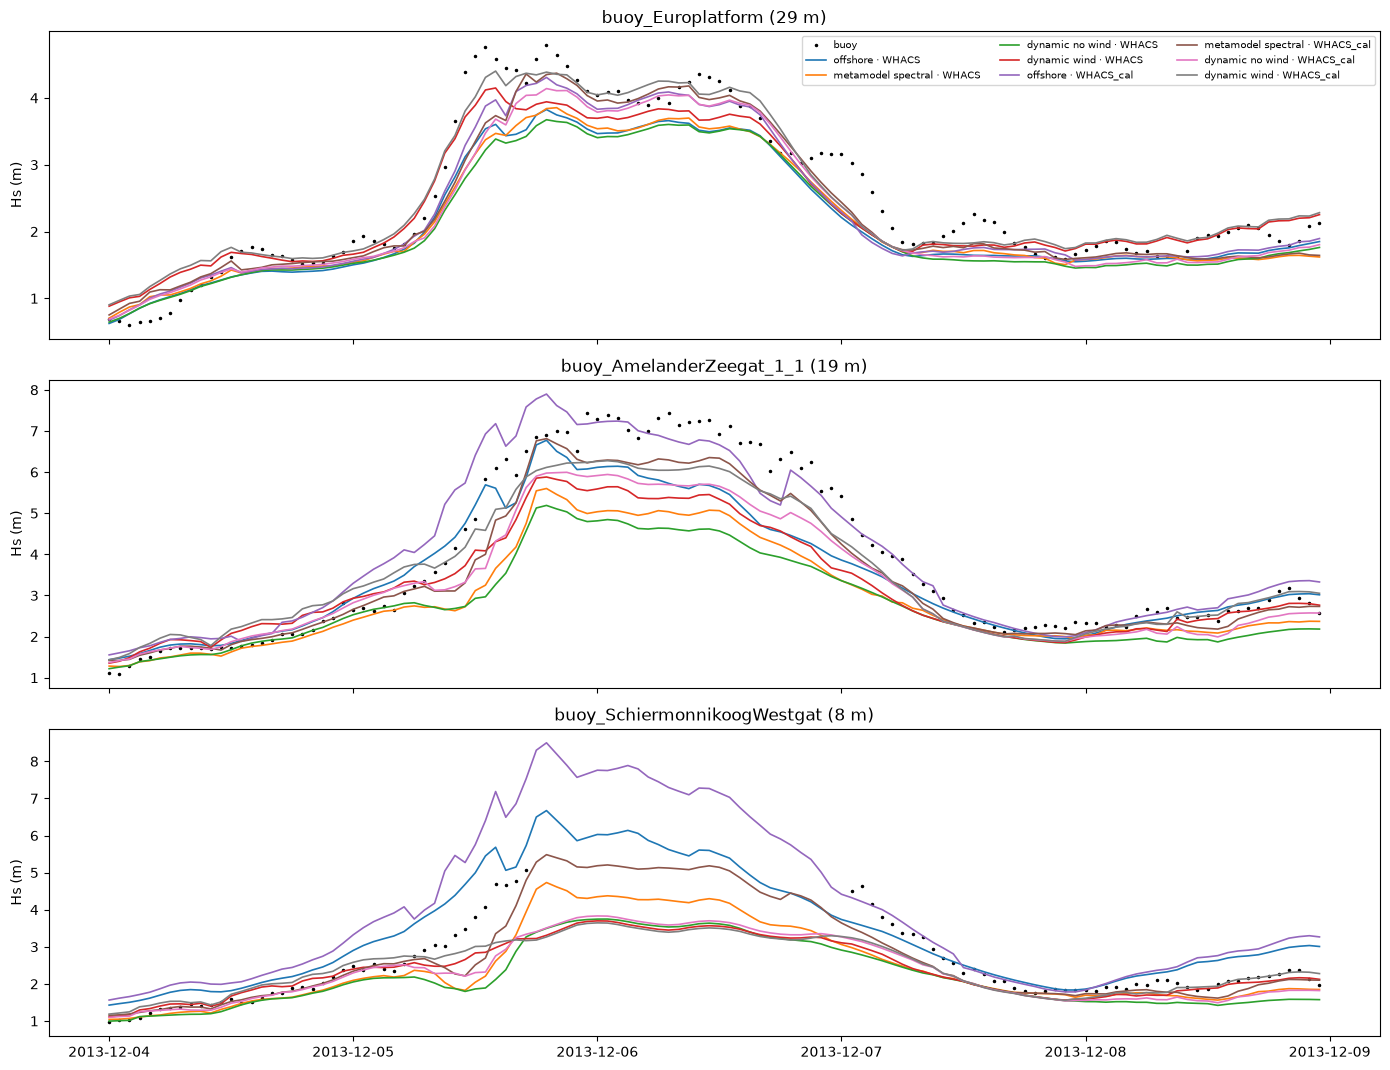

In [ ]:
window = EVENTS["Xaver"]
obs = buoy["hs"].sel(time=window)
have = obs.notnull().sum("time") > 24
depth = (
    buoy["site_mesh_depth"]
    .where(have, drop=True)
    .sortby(buoy["site_mesh_depth"].where(have, drop=True))
)
picks = [str(depth.sites.values[i]) for i in (-1, len(depth) // 2, 0)]
fig, axes = plt.subplots(len(picks), 1, figsize=(14, 3.6 * len(picks)), sharex=True)
for ax, site in zip(axes, picks):
    ax.plot(obs.time, obs.sel(sites=site), "k.", ms=3, label="buoy")
    for name, field in estimates.items():
        ax.plot(
            field.time.sel(time=window),
            field["hs"].sel(sites=site, time=window),
            lw=1.2,
            label=name,
        )
    ax.set(
        ylabel="Hs (m)",
        title=f"{site} ({float(buoy['site_mesh_depth'].sel(sites=site)):.0f} m)",
    )
axes[0].legend(fontsize=7, ncol=3)
fig.tight_layout()
plt.show()

## 3 · Maps at the Xaver peak

Hs at the isobaths at the hour of the highest site-mean Hs in the dynamic run with wind
(WHACS), for each estimate, and their differences to that run.

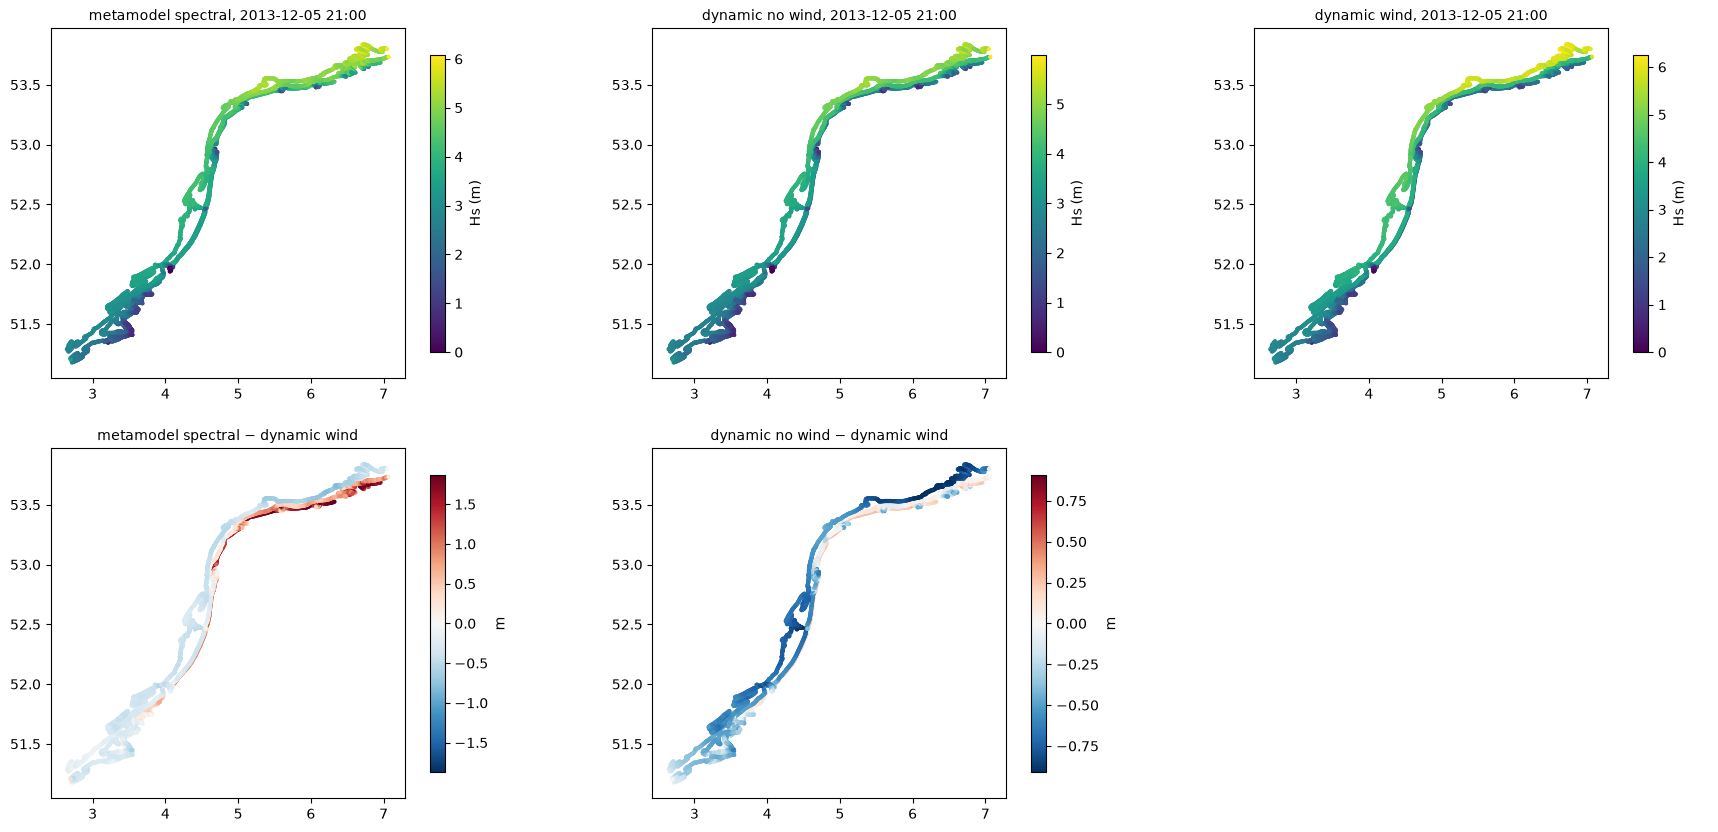

In [ ]:
OFF = "WHACS"
window = EVENTS["Xaver"]
iso = rs.metamodel(OFF, "isobaths", True).sel(time=window)
sites = iso.sites.values
runs = {
    "metamodel spectral": iso,
    "dynamic no wind": rs.dynamic(OFF, False, sites).sel(time=window),
    "dynamic wind": rs.dynamic(OFF, True, sites).sel(time=window),
}
peak = runs["dynamic wind"]["hs"].mean("sites").idxmax("time").values
coords = iso["hs"].isel(time=0, drop=True).coords
ref = runs["dynamic wind"]["hs"].sel(time=peak).assign_coords(coords)
fig, axes = plt.subplots(2, 3, figsize=(22, 10))
for ax, (name, field) in zip(axes[0], runs.items()):
    rs.plot_site_map(
        field["hs"].sel(time=peak).assign_coords(coords),
        f"{name}, {pd.Timestamp(peak):%Y-%m-%d %H:%M}",
        "Hs (m)",
        cmap="viridis",
        vmin=0,
        ax=ax,
    )
for ax, (name, field) in zip(axes[1], runs.items()):
    if name == "dynamic wind":
        ax.axis("off")
        continue
    rs.plot_site_map(
        field["hs"].sel(time=peak).assign_coords(coords) - ref,
        f"{name} − dynamic wind",
        "m",
        ax=ax,
    )
plt.show()